# Chapter 7. The final configuration, and how it compares

**Covers** (original notebooks v2/03, v2/04, v2/08, v2/09 and the
benchmark analyses):
1. the configuration and its headline;
2. where the return comes from;
3. the stop-loss, re-derived against this configuration;
4. four ideas tested after the configuration was fixed;
5. managed-futures benchmarks, compared fairly;
6. the return-stacked ETF this project set out to replicate.

```python
build_trend_nav(df, symbols=A12, apply_costs=True,
                hrp=True, universe=buckets(A12), hrp_lag=1,
                rebalance_freq="M", base_target_vol=0.13,
                regime_gate=True, regime_mult_mode="learned",
                regime_features=("vol", "corr", "er", "disp", "agree"),
                regime_auto_k=(2, 10), regime_kmeans="portable")
```

In [1]:
from _setup import *
from cta.walkforward import two_year_windows, nested
from cta.engine import LAST_STOP_STATS
from ctadata.paths import data_dir
from ctadata.benchmarks import load_mbxax, load_nilssonhedge_cta, load_sg_trend_index, load_rsst

UNI = buckets(A12)
KW = {**DEFAULT_PARAMS, **CHOSEN, "universe": UNI}
WINDOWS = two_year_windows(df.index, OOS)
r = chosen()
describe({"S&P alone": SPX, "sleeve (chosen)": r, "S&P + sleeve": SPX + r})

,sharpe,vol,cagr,max_dd
S&P alone,0.5455,0.1947,0.1096,-0.4251
sleeve (chosen),0.4349,0.1225,0.0634,-0.2693
S&P + sleeve,0.7357,0.2359,0.1781,-0.3370


The sleeve on its own is a modest return stream and was never meant to be
held alone. Stacked on the S&P it raises the return of the combined book.
Remember Chapter 4: this headline carries a selection premium of about
0.19 Sharpe, so a live expectation is nearer 0.35 than the figure above.

## 2. Where the return comes from

Attribution is recorded inside the engine's loop (`collect_contrib=True`),
from the same quantities that form each day's return, so it reconciles to
the NAV exactly. Computing it from the returned weights would be wrong:
those are TARGET weights, not the positions actually held.

In [2]:
nav, lev, w, contrib, cost = build_trend_nav(df, symbols=A12, collect_contrib=True, **KW)
err = (contrib.sum(axis=1) - cost.sum(axis=1) - returns(nav)).abs().max()
print(f"attribution reconciles to the NAV within {err:.1e}")
net = (contrib - cost).loc[OOS:]
by_mkt = net.sum().sort_values()
cls_of = {s: k for k, v in UNI.items() for s in v}
by_cls = by_mkt.groupby(cls_of).sum()
pd.DataFrame({"contribution, % of NAV (summed)": by_cls * 100}).round(2)

attribution reconciles to the NAV within 1.7e-16


,"contribution, % of NAV (summed)"
commodities,74.0400
currencies,11.1500
equities,34.1500
fixed_income,5.5600


In [3]:
by_mkt.mul(100).round(2).rename("% of NAV").to_frame().T

,gbp,silver,wti,aud,nikkei,us10y,spx,brent,jpy,nasdaq,copper,gold
% of NAV,-4.9400,-0.6400,1.2700,1.9300,4.7400,5.5600,11.8500,12.2300,14.1700,17.5600,26.2300,34.9500


Commodities, gold and copper above all, carry most of the return. Fixed
income (one market) contributes least and sterling is a net loser over the
period. Neither is a reason to cut: fixed income is a diversifier rather
than a return source (in the original analysis, removing it deepened the
drawdown in every configuration tested), and cutting the losers is exactly
the selection-on-the-sample error of Chapter 4.

In [4]:
yearly = r.loc[OOS:].groupby(r.loc[OOS:].index.year).apply(lambda s: (1 + s).prod() - 1)
spx_y = SPX.loc[OOS:].groupby(SPX.loc[OOS:].index.year).apply(lambda s: (1 + s).prod() - 1)
pd.DataFrame({"sleeve": yearly, "S&P": spx_y}).mul(100).round(1).T

date,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
sleeve,21.0000,2.6000,4.7000,-1.7000,-11.1000,17.3000,3.3000,0.8000,-7.6000,36.1000,3.3000,0.0000,16.8000,8.9000,13.1000,-10.5000,7.1000,18.1000,3.3000
S&P,-30.1000,32.7000,12.5000,1.4000,9.2000,25.5000,11.1000,-2.3000,8.2000,19.1000,-4.6000,33.8000,15.9000,27.9000,-18.2000,29.4000,25.8000,13.2000,13.1000


## 3. The stop-loss, re-derived against this configuration

The 3x ATR stop in Chapter 5 was tested against the plain sleeve. But a
stop and the regime gate are substitutes, both cut risk, so the width has
to be re-derived against the configuration actually run. Seven widths, the
exit charged at the cost table, and two re-entry rules: wait for the next
rebalance, or re-enter the day the score changes. Results at matched
volatility, since a stop changes the book's size.

In [5]:
stops = {"no stop": r}
fires = {}
for m in (3, 5, 8, 12):
    stops[f"{m}x, wait"] = returns(build_trend_nav(df, symbols=A12, trailing_stop=True,
                                                   atr_multiplier=m, stop_cost=True, **KW)[0])
    fires[f"{m}x, wait"] = LAST_STOP_STATS.get("fires", 0)
stops["3x, re-enter on signal"] = returns(build_trend_nav(df, symbols=A12, trailing_stop=True,
                                                          atr_multiplier=3, stop_cost=True,
                                                          stop_reentry="signal", **KW)[0])
years = len(r.loc[OOS:]) / 252
t = describe(stops, match_to="no stop")
t["fires_per_year"] = pd.Series({k: v / years for k, v in fires.items()})
t

,sharpe,vol,cagr,max_dd,cagr_vm,max_dd_vm,fires_per_year
no stop,0.4349,0.1225,0.0634,-0.2693,0.0634,-0.2693,NaN
"3x, wait",0.3608,0.1096,0.0501,-0.2492,0.0553,-0.2760,33.2800
"5x, wait",0.3968,0.1159,0.0563,-0.2553,0.0591,-0.2680,20.5505
"8x, wait",0.4391,0.1192,0.0628,-0.2793,0.0643,-0.2861,8.6841
"12x, wait",0.4278,0.1216,0.0621,-0.2700,0.0625,-0.2717,2.2654
"3x, re-enter on signal",0.3211,0.1152,0.0467,-0.2717,0.0492,-0.2863,NaN


In [6]:
picks, chain, base_chain = nested(stops, WINDOWS, OOS, rf=RF, base="no stop")
print("width chosen per window:", picks.chose.tolist())
pd.DataFrame({"width picked per window": stats(chain, RF), "no stop": stats(base_chain, RF)}).T

width chosen per window: ['3x, wait', '3x, wait', '3x, wait', '3x, wait', '3x, wait', '3x, wait', '5x, wait', '8x, wait', '8x, wait']


,sharpe,vol,cagr,max_dd
width picked per window,0.3235,0.1095,0.0458,-0.2492
no stop,0.3618,0.1203,0.0532,-0.2693


No width meaningfully beats no stop. Tight stops lose clearly; wide ones
(8x, 12x) fire a few times a year and land within noise of no stop, one a
hair above and one below. Re-entering on a new signal is worse at the same
width: a stop fires on a pullback while the trend is intact, the score has
not changed, so the re-entry buys the reversal. Picking the width per
window mostly picks the tightest, and loses.

The book already controls risk three ways (each position sized to its own
volatility, the book sized to a target, the regime gate). A per-position
stop on top removes positions in intact trends. **No stop in the strategy.**
The live account carries a 10x daily-ATR rail on the broker's server, which
fires a few times a year and costs nothing measurable; it is there for what
a backtest cannot see (a weekend gap, the terminal down).

## 4. Four ideas tested after the configuration was fixed

Each reshapes the existing signal rather than adding information.

In [7]:
late = {
    "chosen (sign)": r,
    "sized signal, continuous": chosen(score_mode="continuous"),
    "sized signal, response": chosen(score_mode="response"),
    "rank regimes by drawdown": chosen(regime_rank_by="drawdown"),
    "no-trade band 20%, edge": chosen(rebalance_band=0.2, band_style="edge",
                                      band_relative=True, band_on_rebal_only=True),
    "hold half size on disagreement": chosen(score_mode="dominant"),
}
rows = {}
for k, v in late.items():
    if k == "chosen (sign)":
        continue
    won = sum(sharpe(v.loc[a:b], RF) > sharpe(r.loc[a:b], RF) for a, b in WINDOWS)
    _, ch, bch = nested({"chosen": r, k: v}, WINDOWS, OOS, rf=RF, base="chosen")
    rows[k] = dict(d_sharpe=sharpe(oos(v), RF) - sharpe(oos(r), RF),
                   windows_won=f"{won}/{len(WINDOWS)}",
                   nested_minus_chosen=sharpe(ch, RF) - sharpe(bch, RF))
pd.DataFrame(rows).T

,d_sharpe,windows_won,nested_minus_chosen
"sized signal, continuous",0.0085,5/9,-0.0372
"sized signal, response",-0.0202,5/9,0.0000
rank regimes by drawdown,-0.0015,2/9,0.0000
"no-trade band 20%, edge",-0.0163,4/9,-0.0198
hold half size on disagreement,-0.0532,5/9,0.0000


All inside the band every rejected layer sits in. Holding a half position
when the two legs disagree is the clearest case: disagreement usually marks
a turning point, and going flat there is the useful part of the signal. The
space of "same signal, different shape" is flat on this book.

## 5. Against managed-futures benchmarks

Two fairness rules, both learned the hard way:
* **sleeve against sleeve.** A stacked book runs about 200% exposure; a
  managed-futures fund does not. The first benchmark comparison set the
  stacked book against unstacked funds and was withdrawn.
* **at the benchmark's own volatility.** Managers do not publish their
  targets, so the sleeve is scaled to each benchmark's realised volatility
  over the benchmark's own window.

In [8]:
def vs(bench_ret, name):
    b = bench_ret.dropna()
    b.index = pd.to_datetime(b.index).tz_localize(None) if getattr(b.index, "tz", None) else pd.to_datetime(b.index)
    s = r.copy(); s.index = s.index.tz_localize(None)
    idx = b.index.intersection(s.index)
    b, s = b.loc[idx], s.loc[idx]
    rf = RF.copy(); rf.index = rf.index.tz_localize(None)
    sm = matched(s, vol(b))
    return {f"{name} ({idx.min():%Y-%m} on)": stats(b, rf),
            f"sleeve at {name}'s vol": stats(sm, rf)}

etf = pd.read_parquet(data_dir() / "cta_etfs_yahoo.parquet")
rows = {}
rows.update(vs(load_mbxax().pct_change(), "MBXAX"))
rows.update(vs(load_nilssonhedge_cta(), "Nilsson Hedge CTA"))
rows.update(vs(load_sg_trend_index().pct_change(), "SG Trend Indicator"))
for t in ("DBMF", "KMLM"):
    rows.update(vs(etf[(t, "adjclose")].pct_change(), t))
pd.DataFrame(rows).T

,sharpe,vol,cagr,max_dd
MBXAX (2015-12 on),0.3213,0.1343,0.0580,-0.3214
sleeve at MBXAX's vol,0.5218,0.1343,0.0869,-0.2540
Nilsson Hedge CTA (2019-01 on),0.4126,0.0814,0.0588,-0.1379
sleeve at Nilsson Hedge CTA's vol,0.3227,0.0814,0.0511,-0.1258
SG Trend Indicator (2006-09 on),0.0443,0.1702,0.0100,-0.5612
sleeve at SG Trend Indicator's vol,0.4268,0.1702,0.0798,-0.3622
DBMF (2019-05 on),0.5985,0.1234,0.0977,-0.2039
sleeve at DBMF's vol,0.4511,0.1234,0.0780,-0.1847
KMLM (2020-12 on),0.3372,0.1474,0.0729,-0.3101
sleeve at KMLM's vol,0.5040,0.1474,0.0995,-0.2578


At each benchmark's own volatility the sleeve earns more than three of the
five (MBXAX, the SG Trend Indicator, KMLM) and less than two (DBMF and the
Nilsson Hedge composite), and its worst loss is shallower than all five.
Theirs are net of fees on real fills; this is a backtest at closing prices. Neither
direction of that comparison is the pitch. The pitch is the stack.

## 6. Against the return-stacked ETF

RSST holds 100% US equities plus 100% trend-following managed futures:
the same structure as the stacked book, so here the stacked comparison IS
fair. Its series is price only (distributions not reinvested), which
understates it by perhaps a point a year; ours charges no management fee.
A futures-based book also earns nothing on its idle collateral, so a second
line adds the T-bill rate.

In [9]:
rsst = load_rsst().pct_change().dropna()
idx = rsst.index.intersection(r.index)
ours = (SPX + r).loc[idx]
funded = ours + RF.loc[idx]
cmp_ = {"RSST (price only, fee inside)": rsst.loc[idx], "ours, stacked": ours,
        "ours, stacked + T-bills on collateral": funded}
print(f"window {idx.min().date()} to {idx.max().date()}, daily correlation "
      f"{rsst.loc[idx].corr(ours):.2f}")
pd.DataFrame({k: stats(v, RF) for k, v in cmp_.items()}).T

window 2023-09-07 to 2026-09-10, daily correlation 0.85


,sharpe,vol,cagr,max_dd
"RSST (price only, fee inside)",0.6872,0.2395,0.1964,-0.3087
"ours, stacked",1.1142,0.1979,0.2765,-0.1887
"ours, stacked + T-bills on collateral",1.3383,0.1979,0.3341,-0.1836


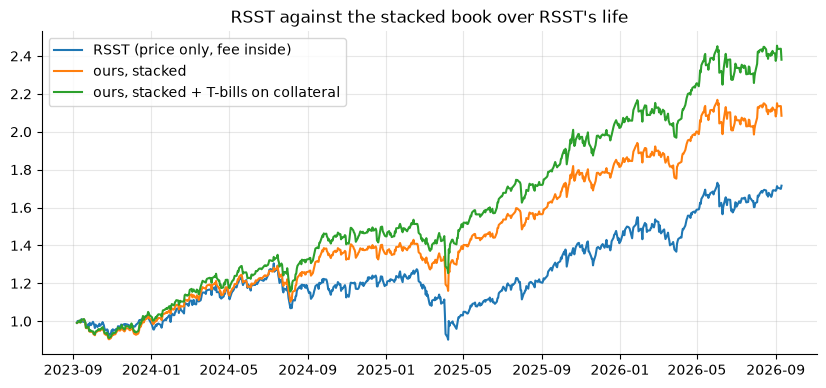

In [10]:
fig, ax = plt.subplots()
for k, v in cmp_.items():
    ax.plot((1 + v).cumprod(), label=k)
ax.set_title("RSST against the stacked book over RSST's life"); ax.legend(); plt.show()

The two track each other closely until April 2025, when RSST's trend book
was long equities into the tariff sell-off. Most of the gap is that one
episode, which is how the gate is supposed to work (insurance that pays
occasionally), and one episode is not a track record.

**How the equity leg is held matters as much as any layer.** With the
sleeve identical, holding the S&P as a CFD (paying the broker's financing
on the full notional every night), as a future, or as the ETF in cash
differs by several points a year, purely from financing compounding. The
live demo holds the dated S&P future, which is what the backtest models;
for real money the equity leg belongs in cash securities, never a CFD.